# Bootstrap 99% confidence interval for the baseline R²

How sure can we be about the surprise-only R²? Koijen & Levy (2026) report every R² with *"99% confidence intervals
based on 1,000 bootstrap samples"*. This notebook does the same for our baseline and compares it with theirs.

- **Regression:** `PRank(r_abn) = a + b * PRank(sue)`, the return rank on the surprise rank (paper's Table 2, column 1).
- **Data:** the pipeline's final dataset (`data/processed/earnings_calls_ibes_<period>.parquet`, built by `uv run doit`),
  in-sample calls only. The period follows `config.yaml`.
- **Bootstrap:** draw N calls with replacement (whole rows, so each call's surprise and return stay paired), refit,
  record R²; repeat B times; the 0.5th and 99.5th percentiles are the 99% interval. The paper does not spell out its
  method beyond "1,000 bootstrap samples", so this is the standard percentile bootstrap.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from llm_based_earnings_surprise_ntam.llm.llm_common import MERGED, SCORES

pd.set_option('display.width', 200)

# Same chart style as the other notebooks; categorical colors in fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

B, SEED = 10_000, 0   # 10,000 resamples for stable bounds; the paper uses 1,000 (compared in section 3)

## 1. Data

One row per earnings call. The regression only uses the two rank columns: `sue_pct_sample` (x) and `r_abn_pct` (y),
both percentile ranks (0-1) within the quarter, over in-sample calls.

In [2]:
df = pd.read_parquet(MERGED)
s = df[df['in_sample']].dropna(subset=['r_abn_pct', 'sue_pct_sample'])
y, x = s['r_abn_pct'].to_numpy(float), s['sue_pct_sample'].to_numpy(float)
N = len(y)

print(f'{MERGED.name}: {len(df):,} calls, {N:,} in sample')
s[['ticker', 'event_date', 'actual', 'consensus', 'sue', 'r_abn', 'sue_pct_sample', 'r_abn_pct']].sample(5, random_state=1).round(4)

earnings_calls_ibes_20251001_20251231_us.parquet: 2,995 calls, 2,584 in sample


,ticker,event_date,actual,consensus,sue,r_abn,sue_pct_sample,r_abn_pct
1781,PANL,2025-11-07,0.92,1.24,-0.0024,-0.0791,0.1745,0.1718
1884,PIHC,2025-11-06,0.72,0.6748,0.0022,-0.0089,0.6722,0.4570
2156,DKLP,2025-11-07,0.85,1.0,-0.0033,-0.0037,0.1563,0.4926
2620,02C9,2025-11-14,-0.45,-0.4332,-0.0006,-0.1012,0.2515,0.1246
809,CHX,2025-10-30,1.52,1.4026,0.0031,0.0097,0.7376,0.5642


## 2. Bootstrap helpers

`draw` makes the resamples once; passing the same draw to several regressions makes their R²s paired (needed later
for ΔR² = R²(LLM + surprise) - R²(surprise)).

In [3]:
def draw(n, B=1000, seed=0):
    """B x n resample indices (rows drawn with replacement)."""
    return np.random.default_rng(seed).integers(0, n, size=(B, n))

def r2(y, X):
    """R² of the OLS of y on X with an intercept."""
    X = np.column_stack([np.ones(len(y)), X])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - np.var(y - X @ beta) / np.var(y)

def boot_r2(y, X, idx):
    """R² on each resample (one per row of idx)."""
    y = np.asarray(y, float)
    X = np.asarray(X, float).reshape(len(y), -1)
    return np.array([r2(y[i], X[i]) for i in idx])

def ci(draws, level=0.99):
    """Percentile interval of the bootstrap draws."""
    a = (1 - level) / 2 * 100
    return tuple(np.percentile(draws, [a, 100 - a]))

## 3. Baseline R² and its 99% interval

With B = 1,000 only 5 draws sit in each 0.5% tail, so the bounds move with the seed. B = 10,000 settles them.

In [4]:
point = r2(y, x)
idx = draw(N, B, SEED)
draws = boot_r2(y, x, idx)
lo, hi = ci(draws)

runs = []
for b_, seed in [(1000, 0), (1000, 1), (B, SEED)]:
    d = draws if (b_, seed) == (B, SEED) else boot_r2(y, x, draw(N, b_, seed))
    runs.append({'B': b_, 'seed': seed, 'R²': point, 'CI low': ci(d)[0], 'CI high': ci(d)[1],
                 'width': ci(d)[1] - ci(d)[0], 'bootstrap mean': d.mean()})
runs = pd.DataFrame(runs)
runs.style.format({c: '{:.3f}' for c in runs.columns if c not in ('B', 'seed')} | {'B': '{:,}'}).hide(axis='index')

B,seed,R²,CI low,CI high,width,bootstrap mean
"1,000",0,0.047,0.024,0.072,0.048,0.048
"1,000",1,0.047,0.029,0.070,0.042,0.048
"10,000",0,0.047,0.027,0.073,0.045,0.048


## 4. Side by side with the paper

Koijen & Levy report the same regression on 1,849 Q4 2025 calls (Benzinga consensus; we use I/B/E/S). Its interval is
[0.03, 0.08] in Tables 3-4 and [0.02, 0.08] in Table 2, for the identical regression, which is the same seed-to-seed
noise seen above. An interval's width shrinks roughly with 1/√N, so ours is rescaled to their N to compare widths.

In [5]:
PAPER = {'r2': 0.050, 'ci': (0.03, 0.08), 'ci_table2': (0.02, 0.08), 'b': 0.219, 'n': 1849}
b_ours = np.polyfit(x, y, 1)[0]

side = pd.DataFrame({
    'Ours': [f'{N:,}', f'{b_ours:.3f}', f'{point:.3f}', f'[{lo:.3f}, {hi:.3f}]', f'{hi - lo:.3f}',
             f'{(hi - lo) * np.sqrt(N / PAPER["n"]):.3f}'],
    'Koijen & Levy (2026)': [f'{PAPER["n"]:,}', f'{PAPER["b"]:.3f}', f'{PAPER["r2"]:.3f}',
                             '[0.03, 0.08]  (Table 2: [0.02, 0.08])', f'{PAPER["ci"][1] - PAPER["ci"][0]:.3f}',
                             f'{PAPER["ci"][1] - PAPER["ci"][0]:.3f}'],
}, index=['N (calls)', 'slope b', 'R²', f'99% CI (ours: B = {B:,})', 'CI width', "CI width at the paper's N"])
print(f"Paper's R² of {PAPER['r2']:.3f} inside our 99% CI: {'yes' if lo <= PAPER['r2'] <= hi else 'NO'}")
side

Paper's R² of 0.050 inside our 99% CI: yes


,Ours,Koijen & Levy (2026)
N (calls),"2,584","1,849"
slope b,0.218,0.219
R²,0.047,0.050
"99% CI (ours: B = 10,000)","[0.027, 0.073]","[0.03, 0.08] (Table 2: [0.02, 0.08])"
CI width,0.045,0.050
CI width at the paper's N,0.054,0.050


## 5. The paper's Figure 1, side by side

Left: the Koijen & Levy bars from their Figure 1 (surprise alone; Gemini 2.5 Flash-Lite and Opus 4.5 each with the
surprise, from Table 3; Opus 4.5 + ACE rulebook on the late half of the quarter). Right: ours, on the same y-axis.
The LLM bars on our side fill in automatically once `llm_score` has scored enough in-sample calls.

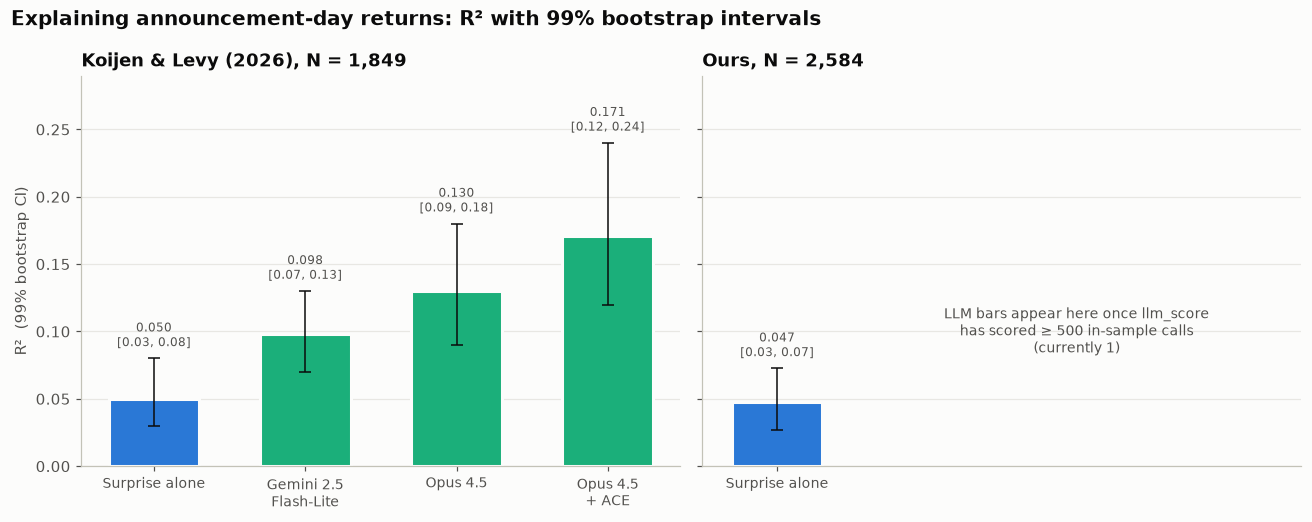

In [6]:
MIN_CALLS = 500   # fewer scored calls than this gives an interval too wide to be useful

paper_bars = [('Surprise alone', 0.050, (0.03, 0.08)),
              ('Gemini 2.5\nFlash-Lite', 0.098, (0.07, 0.13)),
              ('Opus 4.5', 0.130, (0.09, 0.18)),
              ('Opus 4.5\n+ ACE', 0.171, (0.12, 0.24))]

our_bars = [('Surprise alone', point, (lo, hi))]
scores = pd.read_parquet(SCORES) if SCORES.exists() else pd.DataFrame(columns=['transcriptid', 'model', 'source', 'prediction'])
n_scored = 0
for (model, source), g in scores.groupby(['model', 'source']):
    m = s.merge(g[['transcriptid', 'prediction']], on='transcriptid').dropna(subset=['prediction'])
    n_scored = max(n_scored, len(m))
    if len(m) >= MIN_CALLS:
        Xm = m[['prediction', 'sue_pct_sample']]
        our_bars.append((f'{model}\n({source})', r2(m['r_abn_pct'].to_numpy(float), Xm.to_numpy(float)),
                         ci(boot_r2(m['r_abn_pct'], Xm, draw(len(m), B, SEED)))))

def bars(ax, rows, title):
    pos = np.arange(len(rows))
    vals = np.array([v for _, v, _ in rows])
    err = np.array([[v - c[0], c[1] - v] for _, v, c in rows]).T
    colors = [BLUE if i == 0 else AQUA for i in range(len(rows))]
    ax.bar(pos, vals, width=0.6, color=colors, edgecolor=SURFACE, linewidth=2)
    ax.errorbar(pos, vals, yerr=err, fmt='none', ecolor=INK, elinewidth=1, capsize=4)
    for p, (_, v, c) in zip(pos, rows):
        ax.text(p, c[1] + 0.006, f'{v:.3f}\n[{c[0]:.2f}, {c[1]:.2f}]', ha='center', va='bottom', fontsize=8, color=INK2)
    ax.set_xticks(pos, [r[0] for r in rows], fontsize=9)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, gridspec_kw={'width_ratios': [4, 4]})
bars(a1, paper_bars, f'Koijen & Levy (2026), N = {PAPER["n"]:,}')
bars(a2, our_bars, f'Ours, N = {N:,}')
a1.set_ylabel('R²  (99% bootstrap CI)')
a1.set_ylim(0, 0.29)
if len(our_bars) == 1:
    a2.set_xlim(-0.5, 3.5)
    a2.text(2, 0.10, f'LLM bars appear here once llm_score\nhas scored ≥ {MIN_CALLS:,} in-sample calls\n'
            f'(currently {n_scored:,})', ha='center', va='center', fontsize=9, color=INK2)
fig.suptitle('Explaining announcement-day returns: R² with 99% bootstrap intervals', x=0.01, ha='left',
             fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

## 6. The baseline intervals, compared directly

Each line is a 99% interval for the same surprise-only regression; the dot is the R². Grey: the paper's two reported
versions. Blue: ours at different B and seeds.

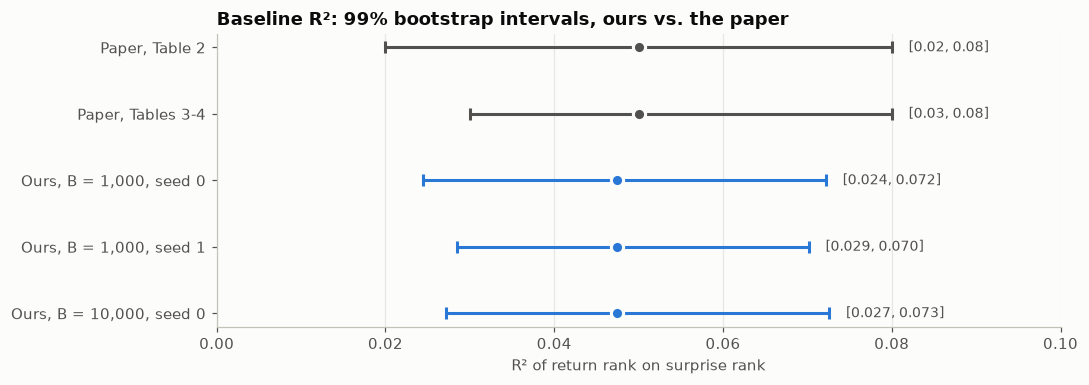

In [7]:
# (label, R², interval, color, decimals): the paper prints its intervals to 2 decimals
rows = [('Paper, Table 2', PAPER['r2'], PAPER['ci_table2'], INK2, 2),
        ('Paper, Tables 3-4', PAPER['r2'], PAPER['ci'], INK2, 2)]
rows += [(f'Ours, B = {int(r.B):,}, seed {int(r.seed)}', r._2, (r._3, r._4), BLUE, 3) for r in runs.itertuples(index=False)]
rows = rows[::-1]   # top to bottom in reading order

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (label, v, (l, h), c, dp) in enumerate(rows):
    ax.errorbar(v, i, xerr=[[v - l], [h - v]], fmt='o', color=c, ecolor=c, elinewidth=2, capsize=4, markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(h + 0.002, i, f'[{l:.{dp}f}, {h:.{dp}f}]', va='center', fontsize=9, color=INK2)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set_xlim(0, 0.1)
ax.set_xlabel('R² of return rank on surprise rank')
ax.grid(axis='y', visible=False)
ax.set_title('Baseline R²: 99% bootstrap intervals, ours vs. the paper')
fig.tight_layout()
plt.show()

## 7. What the bootstrap produced

The histogram is all the resampled R² values. The 99% interval keeps the middle 99% of them. The paper's interval
(grey band) is drawn on top for comparison.

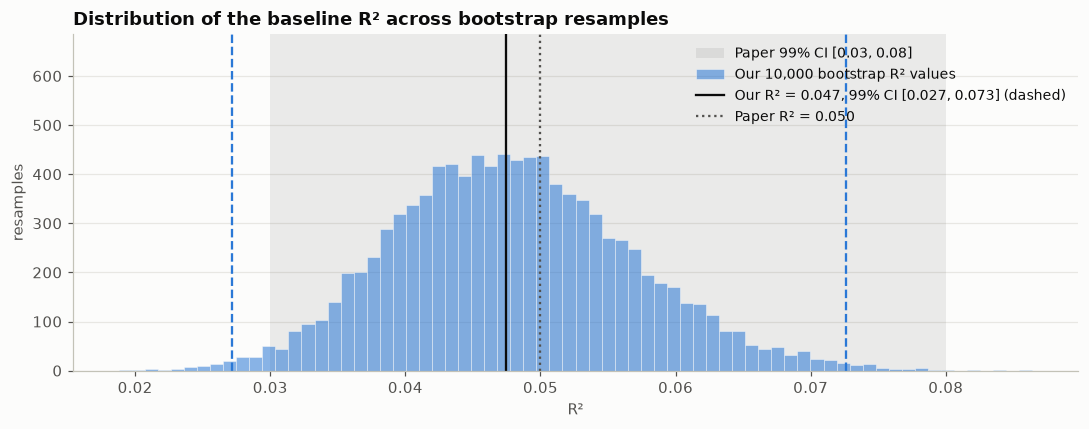

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(*PAPER['ci'], color=INK2, alpha=0.10, lw=0, label=f'Paper 99% CI [{PAPER["ci"][0]:.2f}, {PAPER["ci"][1]:.2f}]')
counts, *_ = ax.hist(draws, bins=70, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.5, label=f'Our {B:,} bootstrap R² values')
for v in (lo, hi):
    ax.axvline(v, color=BLUE, ls='--', lw=1.5)
ax.axvline(point, color=INK, lw=1.5, label=f'Our R² = {point:.3f}, 99% CI [{lo:.3f}, {hi:.3f}] (dashed)')
ax.axvline(PAPER['r2'], color=INK2, lw=1.5, ls=':', label=f'Paper R² = {PAPER["r2"]:.3f}')
ax.set_xlabel('R²')
ax.set_ylabel('resamples')
ax.set_ylim(0, counts.max() * 1.55)   # headroom so the legend sits above the bars
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Distribution of the baseline R² across bootstrap resamples')
fig.tight_layout()
plt.show()

## 8. Takeaways

- **The paper's 5.0% lies inside our 99% interval**, so the 0.3pp gap between our R² and theirs is within noise.
- **Our interval sits slightly lower**, by about the same 0.3pp as the point estimate, and is **narrower** because we
  have more calls; rescaled to the paper's 1,849 calls its width matches theirs.
- **B = 1,000 bounds move by ~0.005 with the seed**, which is also why the paper prints [0.02, 0.08] in one table and
  [0.03, 0.08] in others for the same regression.

**Next:** in `llm_eval`, reuse the same `idx` for the baseline and the LLM regressions on the same calls, and report
`ci(boot_r2(y, X_both, idx) - boot_r2(y, X_sue, idx))` as the interval for ΔR². Overlapping R² intervals is a weak
test; the paired ΔR² interval is the direct one.